<a href="https://colab.research.google.com/github/ivdevera/L03-tree-stability/blob/main/L03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Isaiah De Vera, William Keenan, Olympia Sauerwein

**Date:** 11/18/26

QUESTION 1

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
import os

if not os.path.exists('L03-tree-stability'):
    !git clone https://github.com/ivdevera/L03-tree-stability.git
df = pd.read_csv('/content/L03-tree-stability/data/heart_failure/heart_failure_clinical_records_dataset.csv')
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6            1  
2       

In [6]:
print(df[["platelets", "creatinine_phosphokinase"]].mode().iloc[0])
print(df[["platelets", "creatinine_phosphokinase"]].mean())

print(df[["creatinine_phosphokinase", "serum_creatinine"]].skew())

df = df.drop(columns="time")
for c in ["creatinine_phosphokinase", "serum_creatinine"]:
    df[c] = np.arcsinh(df[c])

features = [c for c in df.columns if c != "DEATH_EVENT"]

platelets                   263358.03
creatinine_phosphokinase       582.00
Name: 0, dtype: float64
platelets                   263358.029264
creatinine_phosphokinase       581.839465
dtype: float64
creatinine_phosphokinase    4.463110
serum_creatinine            4.455996
dtype: float64


QUESTION 2

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression

seed = 100
shuffled = df.sample(frac=1, random_state=seed)
train_size = int(0.8 * len(shuffled))
train = shuffled.iloc[:train_size]
test = shuffled.iloc[train_size:]
X_train, y_train = train[features], train["DEATH_EVENT"]
X_test, y_test = test[features], test["DEATH_EVENT"]

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=200)
tree.fit(X_train, y_train)
linear = LinearRegression().fit(X_train, y_train)

tree_prediction = tree.predict_proba(X_test)[:, 1]
linear_prediction = linear.predict(X_test)

In [8]:
from sklearn.metrics import accuracy_score

majority = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.repeat(majority, len(y_test)))
tree_accuracy = accuracy_score(y_test, tree_prediction > 0.5)
linear_accuracy = accuracy_score(y_test, linear_prediction > 0.5)

print("Training:", len(train), "Test:", len(test))
print(f"Always {majority}: {baseline_accuracy:.1%}")
print(f"Tree: {tree_accuracy:.1%}")
print(f"Linear: {linear_accuracy:.1%}")

Training: 239 Test: 60
Always 0: 65.0%
Tree: 70.0%
Linear: 71.7%


On the seed-100 test set of 60 patients, always predicting survival was correct 65% of the time. The tree scores 70% and the linear model scores 71.7%, meaning both surpass the baseline by a few percentage points. With 60 test rows each patient is worth ~1.7 points, so the tree and linear model differ only by one patient.

QUESTION 3

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

In [10]:
seeds = [100, 101, 102, 103]
trees, linears, accuracies = [], [], []
tree_predictions = np.zeros((len(seeds), len(X_test)))
linear_predictions = np.zeros((len(seeds), len(X_test)))

In [11]:
for i, sd in enumerate(seeds):
    shuffled = df.sample(frac=1, random_state=sd)
    tr = shuffled.iloc[:train_size]
    te = shuffled.iloc[train_size:]
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=200)
    tree.fit(tr[features], tr["DEATH_EVENT"])
    linear = LinearRegression().fit(tr[features], tr["DEATH_EVENT"])
    trees.append(tree)
    linears.append(linear)
    tree_predictions[i] = tree.predict_proba(X_test)[:, 1]
    linear_predictions[i] = linear.predict(X_test)
    accuracies.append({
        "seed": sd,
        "tree": accuracy_score(te["DEATH_EVENT"], tree.predict(te[features])),
        "linear": accuracy_score(te["DEATH_EVENT"], linear.predict(te[features]) > 0.5),
        "always 0": accuracy_score(te["DEATH_EVENT"], np.repeat(tr["DEATH_EVENT"].mode().iloc[0], len(te))),
    })

pd.DataFrame(accuracies).round(3)

,seed,tree,linear,always 0
0,100,0.700,0.717,0.650
1,101,0.733,0.750,0.633
2,102,0.700,0.717,0.767
3,103,0.750,0.833,0.733


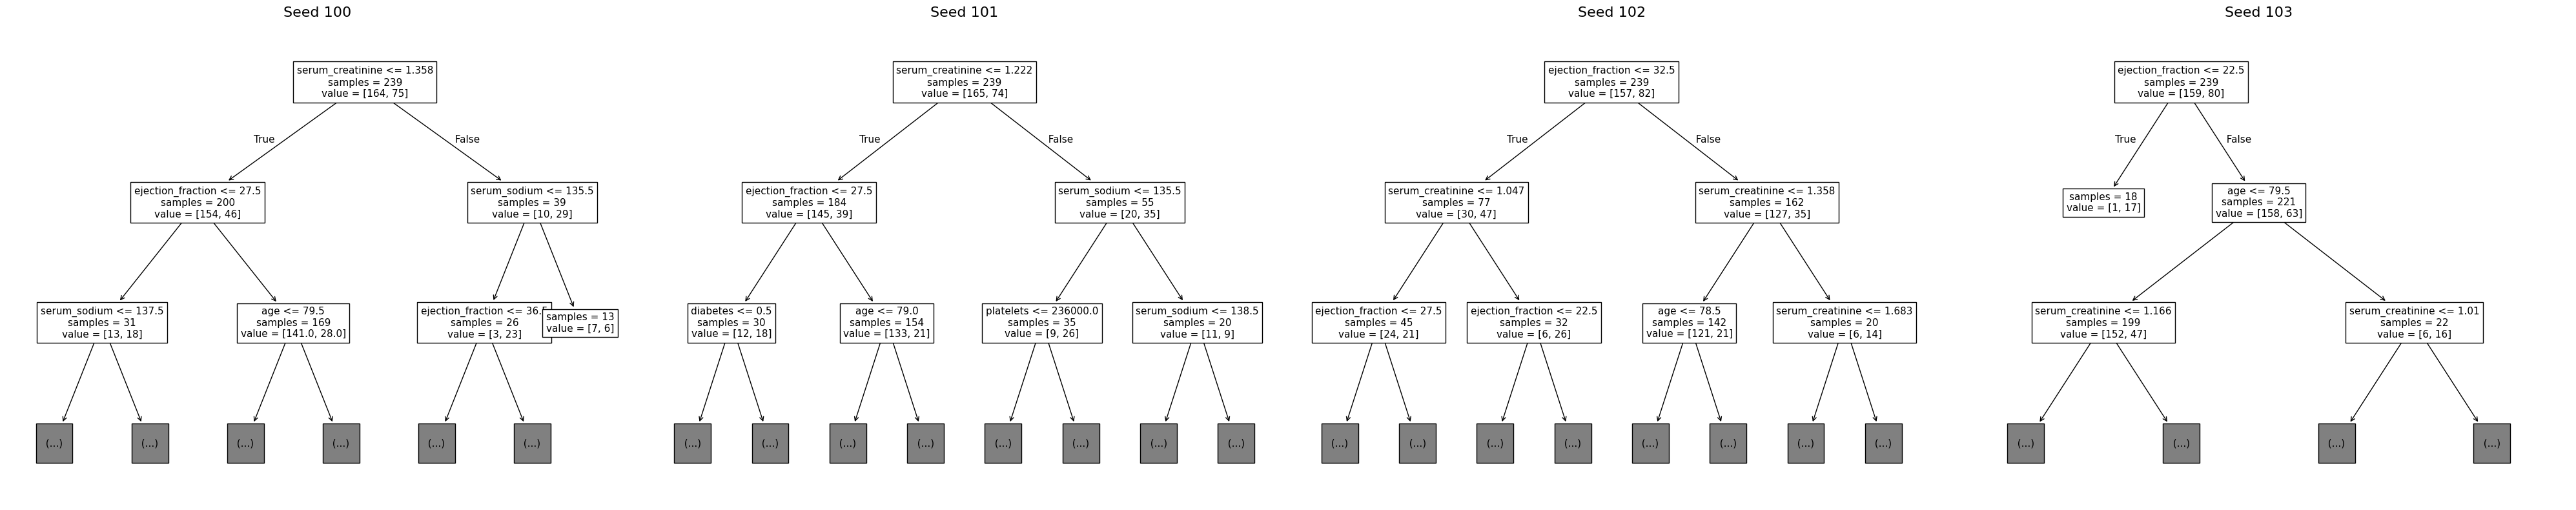

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(40, 8))
for ax, tree, sd in zip(axes, trees, seeds):
    plot_tree(tree, feature_names=features, max_depth=2, ax=ax, fontsize=11, impurity=False)
    ax.set_title(f"Seed {sd}", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
pd.DataFrame({sd: m.coef_ for sd, m in zip(seeds, linears)}, index=features).round(3)

,100,101,102,103
age,0.009,0.006,0.008,0.009
anaemia,0.085,0.071,0.081,0.042
creatinine_phosphokinase,0.041,0.019,0.049,0.039
diabetes,0.065,0.022,0.002,0.007
ejection_fraction,-0.009,-0.011,-0.011,-0.009
high_blood_pressure,0.074,0.110,0.113,0.071
platelets,-0.000,-0.000,0.000,-0.000
serum_creatinine,0.394,0.372,0.275,0.326
serum_sodium,-0.008,-0.007,-0.009,-0.006
sex,-0.051,-0.070,-0.070,-0.106


The trees notably differ for each seed. Seeds 100 and 101 split on serum_creatinine first at different cutoffs, while seeds 102 and 103 split on ejection_fraction first, and seed 103 has a single leaf on one side where the other three continue splitting. Below the root, each tree uses a different combination of features including age, platelets, serum_sodium, and diabetes. The linear coefficients are much more similar among the four different seeds. serum_creatinine remains the largest across the seeds and ejection_fraction is relatively constant with most signs agreeing. Some of the weaker variables vary more, such as diabetes moving from 0.002 to 0.065 or smoking changing sign. Overall, the appearance of the trees changes a lot where the linear model changes much less.

QUESTION 4:

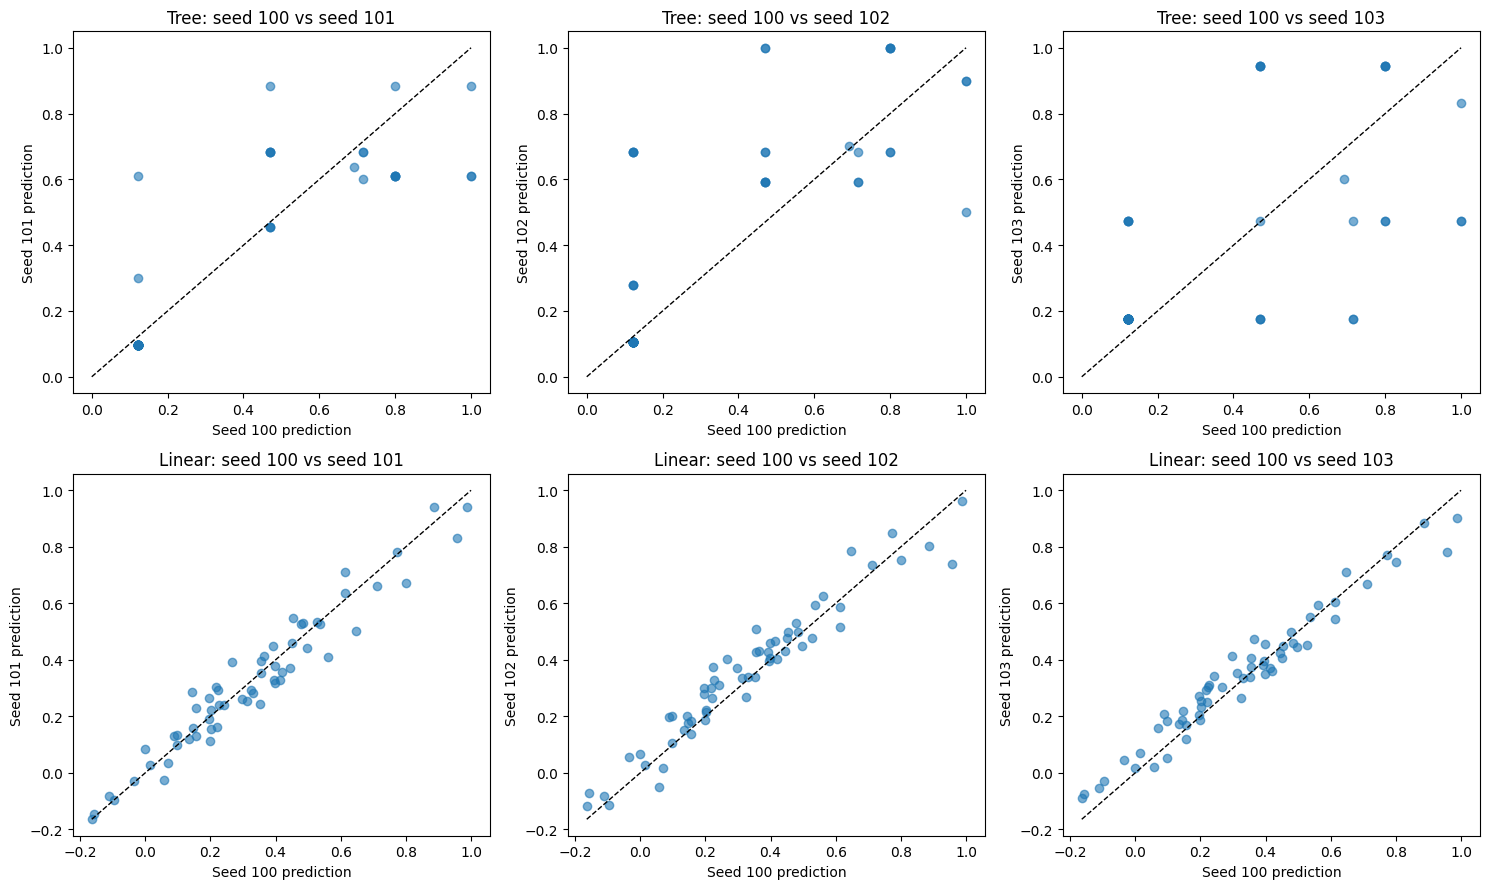

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (name, preds) in enumerate([("Tree", tree_predictions), ("Linear", linear_predictions)]):
    for col, sd in enumerate(seeds[1:]):
        ax = axes[row, col]
        ax.scatter(preds[0], preds[col + 1], alpha=0.6)
        lo, hi = min(preds.min(), 0), max(preds.max(), 1)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_xlabel("Seed 100 prediction")
        ax.set_ylabel(f"Seed {sd} prediction")
        ax.set_title(f"{name}: seed 100 vs seed {sd}")
plt.tight_layout()
plt.show()

The linear predictions are all very similar. For all three alternative seeds the points are all along a a pretty tight line at a roughly 45 degree angle. The tree plots look messier though. Each tree only predicts 5 to 8 distinct values, so the 60 test patients are pretty scattered. Some of those points are very far from the diagonal. For example, patients the seed-100 tree gives 0.12 get 0.61 from seed 101 and 0.68 from seed 102. Seed 101 tracks the diagonal the best, and seed 103 is the most scattered. The trees still roughly agree on who is low-risk and who is high-risk, but they're clearly less similar than the linear models.

In [15]:
correlations = pd.DataFrame({
    "tree": [np.corrcoef(tree_predictions[0], tree_predictions[i])[0, 1] for i in range(1, len(seeds))],
    "linear": [np.corrcoef(linear_predictions[0], linear_predictions[i])[0, 1] for i in range(1, len(seeds))],
}, index=seeds[1:])
correlations.round(3)

,tree,linear
101,0.882,0.968
102,0.807,0.967
103,0.663,0.979


The linear models are highly correlated with the seed-100 model, at 0.968, 0.967, and 0.979 for seeds 101, 102, and 103. The trees are lower at 0.882, 0.807, and 0.663. Seed 101's tree is still fairly strongly correlated, but seed 103's tree is only moderately correlated, since it has a value of .663. That makes sense since it's the tree from Q3 that stops splitting on one side of the root. So the linear predictions are almost interchangeable, while the tree predictions are positively related but much less consistent.

In [16]:
regressions = []
for name, preds in [("tree", tree_predictions), ("linear", linear_predictions)]:
    for i, sd in enumerate(seeds[1:], start=1):
        fit = LinearRegression().fit(preds[0].reshape(-1, 1), preds[i])
        regressions.append({
            "model": name,
            "seed": sd,
            "intercept": fit.intercept_,
            "slope": fit.coef_[0],
            "R2": fit.score(preds[0].reshape(-1, 1), preds[i]),
        })
pd.DataFrame(regressions).round(3)

,model,seed,intercept,slope,R2
0,tree,101,0.039,0.826,0.777
1,tree,102,0.091,0.912,0.651
2,tree,103,0.147,0.623,0.440
3,linear,101,0.018,0.926,0.937
4,linear,102,0.057,0.910,0.935
5,linear,103,0.061,0.862,0.958


For the linear models, the intercepts are close to zero (0.018, 0.057, 0.061) and the slopes are fairly close to 1 (0.926, 0.910, 0.862). The R^2 values are close to 1 (0.937, 0.935, 0.958). The slopes being a little under 1 means the other models are a little less extreme than the seed-100 model, but the difference is pretty insignificant and small. For the trees, the intercepts are farther from zero (0.039, 0.091, 0.147) and the slopes range from 0.826 to 0.912 down to 0.623 for seed 103. The R^2 values are only 0.777, 0.651, and 0.440. So the linear models pass all three checks, while the trees only come somewhat close for seed 101 and don't work well for seed 103.

QUESTION 5:

The linear models have similar coefficients and predictions across the splits. The coefficients stay in about the same range for each seed, and the predictions on the seed-100 test set have correlations around 0.97 with R^2 values between 0.94 and 0.96. The intercepts are near 0 and the slopes are near 1. The trees do not. Each seed gives a different tree, with different root splits, cutoffs, and features below the root. Their predictions are also less consistent, with correlations from 0.66 to 0.88 and R^2 values from 0.44 to 0.78. The trees still roughly agree on which patients are higher risk, but their predictions change much more than the linear models. Overall, the linear models are stable across splits where the trees are not.

QUESTION 6:

False for this dataset. The trees changed a lot in appearance across seeds, and their predictions on the seed-100 test set also changed. The correlations with the seed-100 tree were between 0.66 and 0.88, and the R^2 values were only 0.44 to 0.78, with seed 103 being the least similar. The trees still agree on the general direction of risk, but their predictions are not very similar. The linear models did give very similar predictions, with correlations around 0.97, but their coefficients also did not change much to begin with. Overall, the models that looked different also predicted differently.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0aadc91e3640cf46f75beefdbc0d8f58f0a7c851
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Please review the code I have provided you alongside the questions and give me a bulleted list of proposed changes and the full AI-assisted solution.
2. make the changes a numbered list, and make the solution a code file, not a ipynb, and keep the original code/structure unless you are making an improvement

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Leakage. Alternative models were trained on about 78% of the seed-100 test rows. Added an overlap printout and a leakage-free check with 30 models.
2. Data loading. The !git clone line and the /content/ path only work in Colab.
3. Cleaning. Added duplicate and binary checks, skew before and after, and a reason for dropping time.
4. Tree settings and prediction rule. One TREE_PARAMS constant and one proba > 0.5 rule.
5. Loop variables. The Q3 loop no longer overwrites tree and linear, and the unused seaborn import is removed.
6. Tree display. Plot full depth-3 trees and add a summary table.
7. Linear coefficients. Added standardized coefficients with a sign-flip flag.
8. Computed numbers. Distinct tree prediction values and maximum disagreement are computed, not typed.
9. Q5 caveat. Added a note that shallow, regularised trees likely understate instability.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | If models could see a lot of the test set, it may skew accuracy, so report overlap |
| 2 | reject | For the scope of this class and for our group, we used Colab, so the original solution works for us |
| 3 | accept | Checks added to ensure data is clean. Before/After skew shown to prove transform did somethinf. Time is recorded after the response, it might give allow the model to peek at the answer. |
| 4 | accept | keep consistent repeated code especially for comaparisons |
| 5 | accept | renaming variables to ensure earlier data like in Q2 is not lost, seaborn not used |
| 6 | accept | the phase 1 trees lost info by maxing the depth too low |
| 7 | accept | raw coefficients depended on the variable's units and some units were so low they rounded to 0. standardizing makes all variables comparable. |
| 8 | accept | typed numbers can go stale. Computing keeps them tied to output |
| 9 | accept | the depth 3 and 10 samples per leaf leads to a fairly stable tree. A caveat of deeper trees being more stable helps add nuance and not assume perfect stability |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6            1  
2       

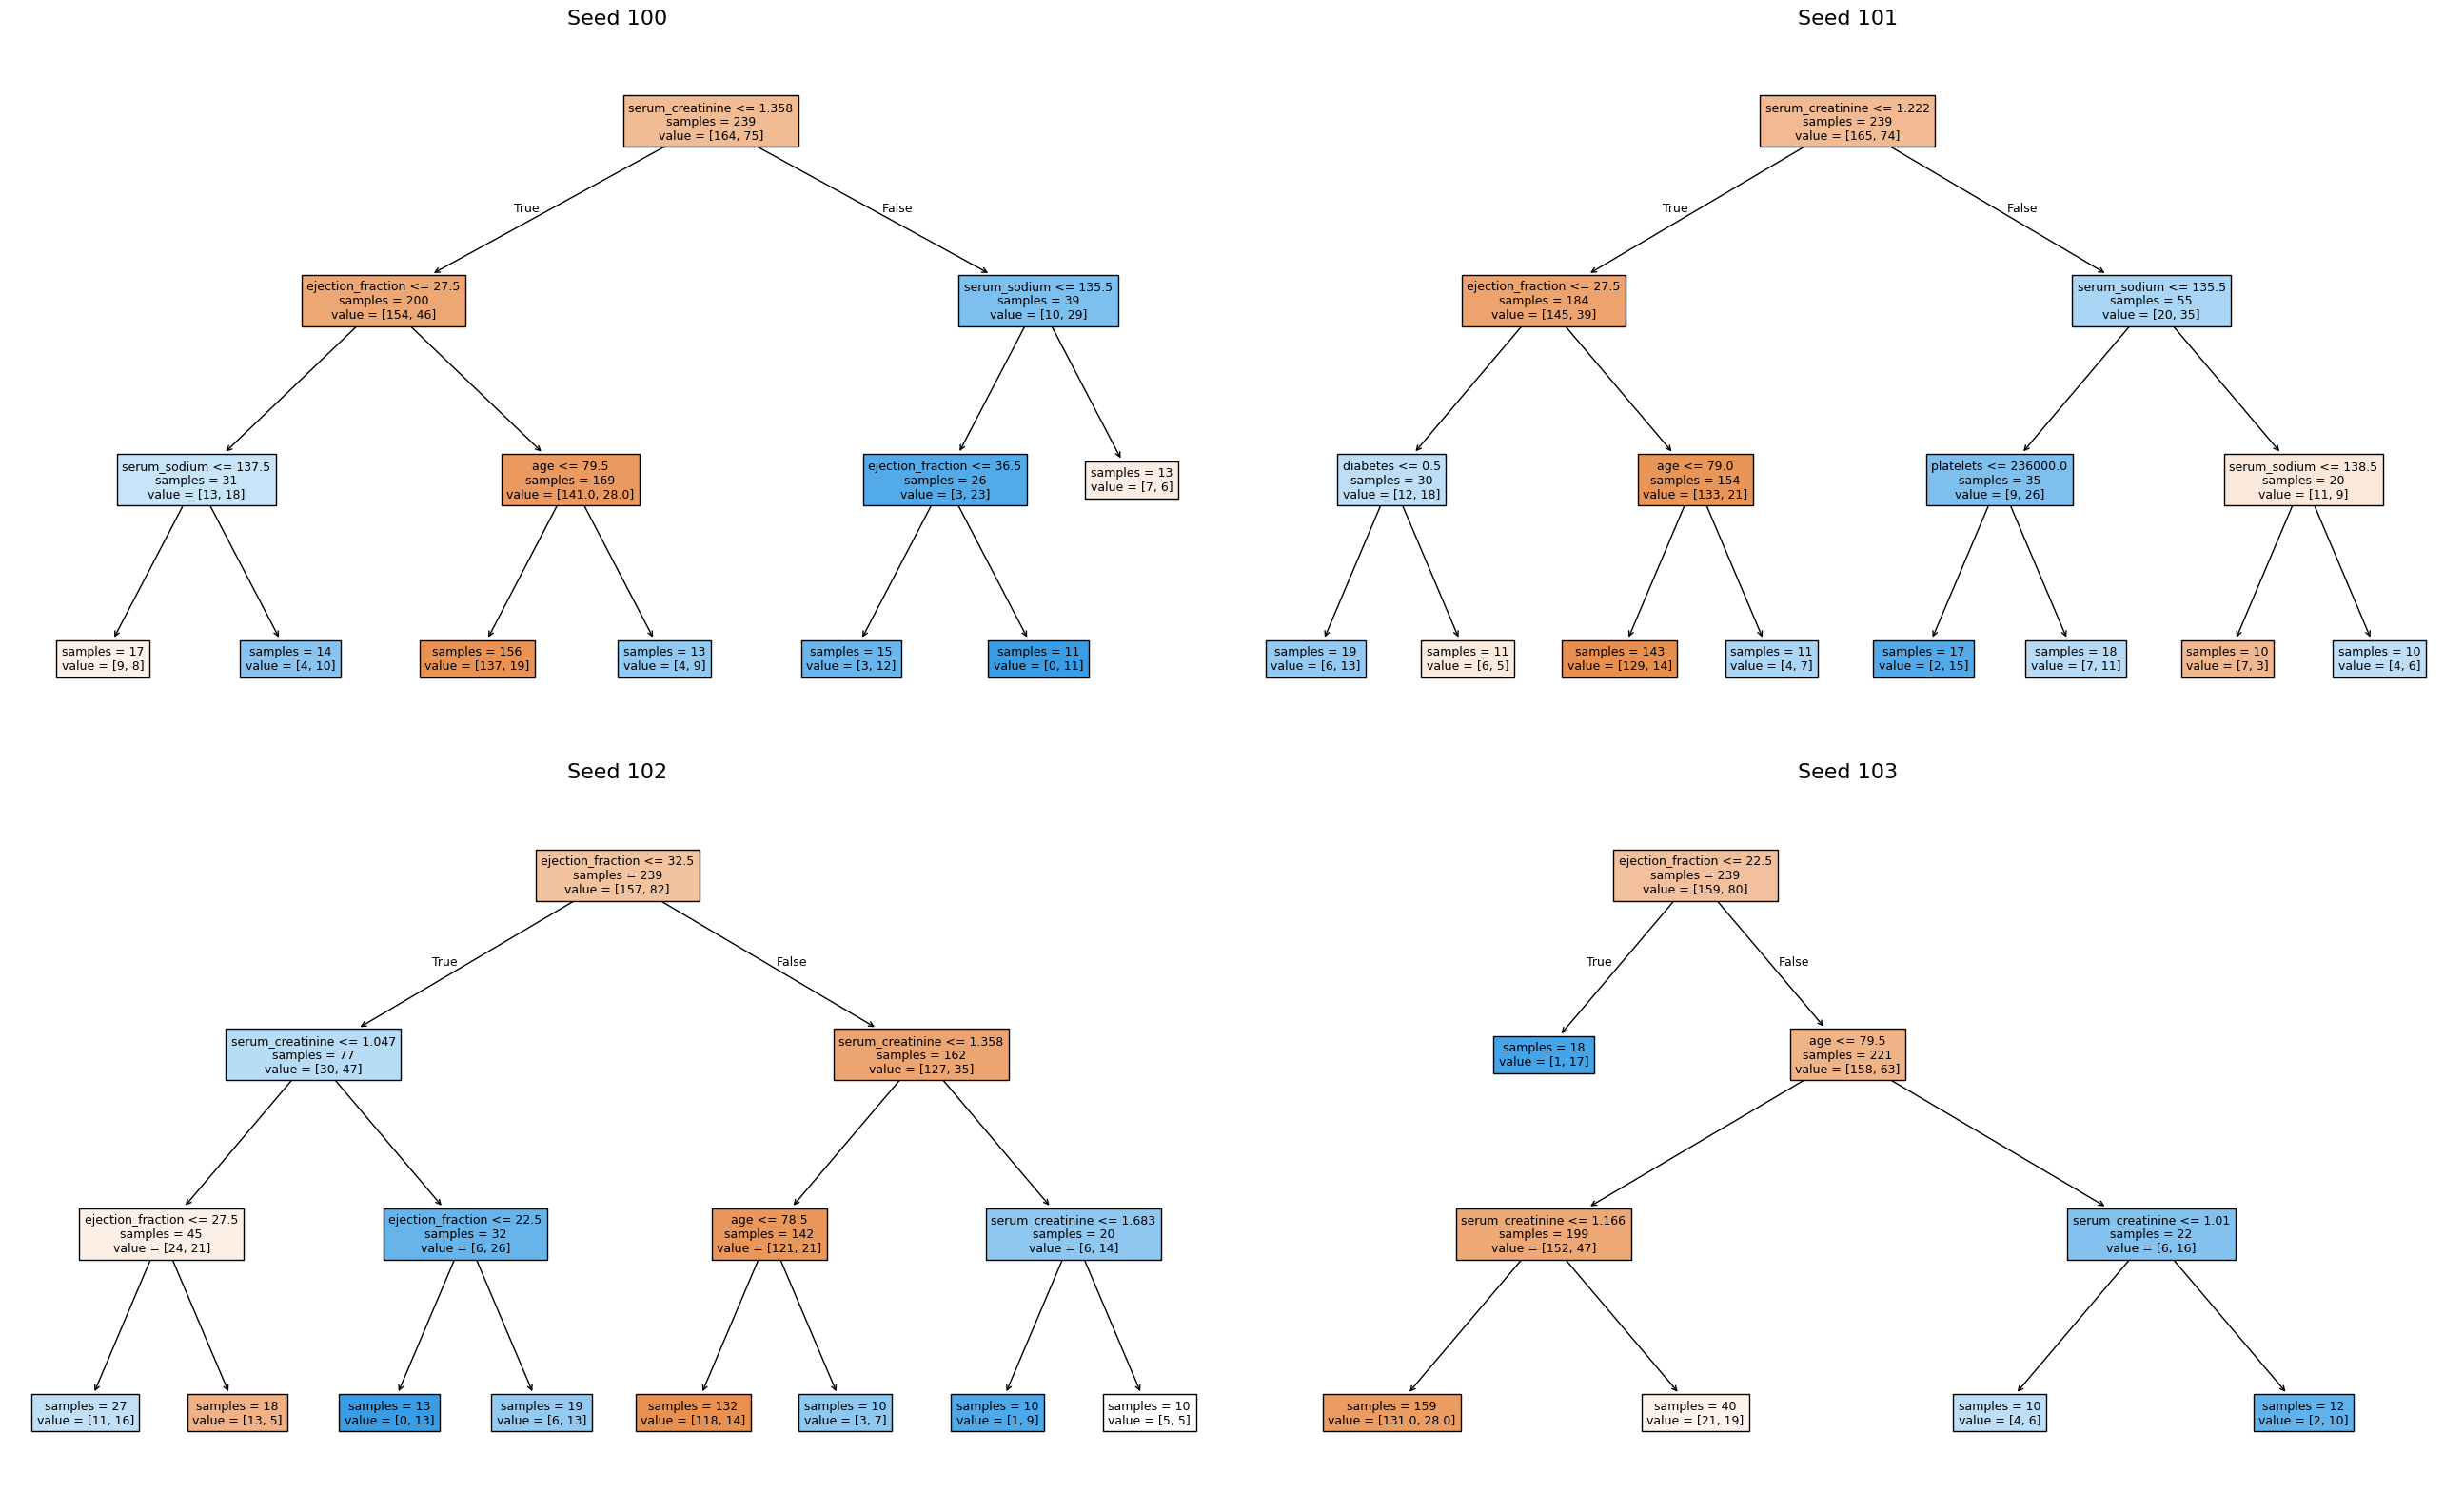

Raw linear coefficients:
                             100     101     102     103
age                       0.0087  0.0057  0.0080  0.0085
anaemia                   0.0850  0.0709  0.0812  0.0417
creatinine_phosphokinase  0.0415  0.0188  0.0495  0.0388
diabetes                  0.0648  0.0219  0.0023  0.0066
ejection_fraction        -0.0088 -0.0109 -0.0115 -0.0088
high_blood_pressure       0.0743  0.1096  0.1134  0.0708
platelets                -0.0000 -0.0000  0.0000 -0.0000
serum_creatinine          0.3937  0.3717  0.2752  0.3262
serum_sodium             -0.0080 -0.0074 -0.0089 -0.0059
sex                      -0.0513 -0.0699 -0.0703 -0.1063
smoking                   0.0281 -0.0022  0.0284  0.0297
Standardized linear coefficients:
                            100    101    102    103  sd across seeds  sign flips
age                       0.105  0.067  0.097  0.103            0.018       False
anaemia                   0.042  0.035  0.041  0.021            0.010       False
creatinine_

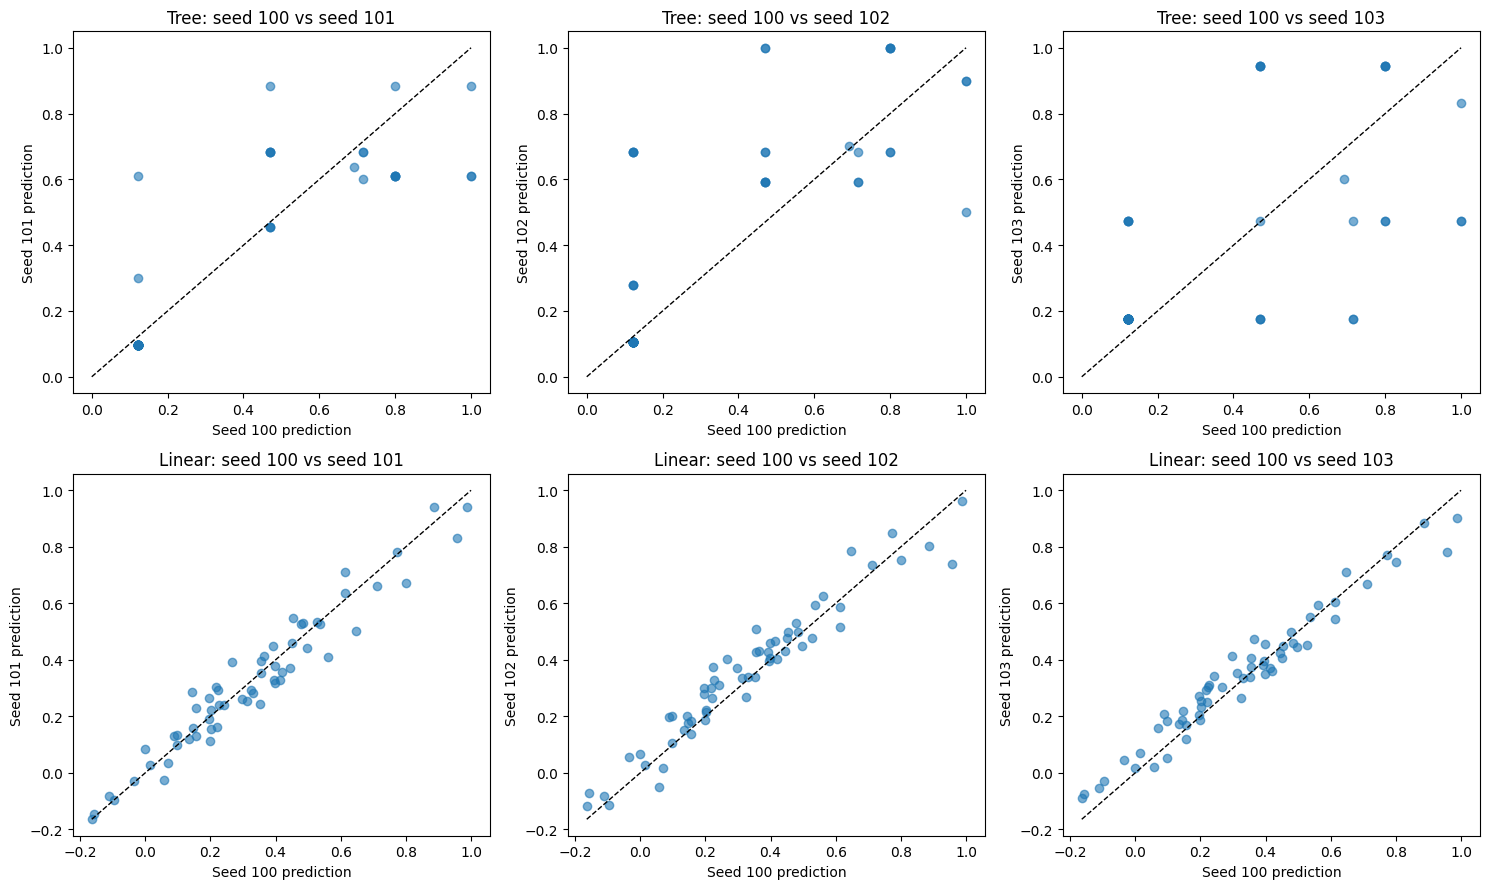

Correlations with the seed-100 model:
      tree  linear
101  0.882   0.968
102  0.807   0.967
103  0.663   0.979
Regression of alternative predictions on seed-100 predictions:
    model  seed  intercept  slope     R2
0    tree   101      0.039  0.826  0.777
1    tree   102      0.091  0.912  0.651
2    tree   103      0.147  0.623  0.440
3  linear   101      0.018  0.926  0.937
4  linear   102      0.057  0.910  0.935
5  linear   103      0.061  0.862  0.958
Leakage-free comparison (30 alternative models per type): median [min, max]
         corr               intercept                slope                   R2              
       median    min    max    median    min    max median    min    max median    min    max
model                                                                                        
linear  0.972  0.944  0.992    -0.014 -0.052  0.010  1.040  0.953  1.164  0.944  0.892  0.984
tree    0.927  0.736  0.999     0.035 -0.018  0.124  0.892  0.680  1.017  0.859  0.5

In [20]:
"""
L03 - Trees and Model Stability: Phase 2 (AI-assisted) solution.

Structure and variable names follow the Phase 1 notebook; changes are marked
with  "# CHANGED (n):"  comments, where n is the number in the 9-point change list.
Written answers to the questions are in comment blocks after each question.
"""

# =============================================================================
# QUESTION 1: look at the data and clean it
# =============================================================================
import os
import subprocess

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# CHANGED (5): unused `import seaborn as sns` removed.

if not os.path.exists('L03-tree-stability'):
    !git clone https://github.com/ivdevera/L03-tree-stability.git
df = pd.read_csv('/content/L03-tree-stability/data/heart_failure/heart_failure_clinical_records_dataset.csv')

print(df.head())
print(df.dtypes)
print(df.isnull().sum())
# CHANGED (3): added duplicate and binary-column checks (Phase 1 printed a mode/mean comparison that did not inform cleaning).
print("duplicate rows:", int(df.duplicated().sum()))
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]
assert all(set(df[c].unique()) <= {0, 1} for c in binary_cols), "unexpected non-binary value"

# CHANGED (3): skew shown before and after the transform.
skew_before = df[["creatinine_phosphokinase", "serum_creatinine"]].skew()
print("skew before transform:\n", skew_before)

# CHANGED (3): reason documented. `time` is the follow-up period; it is only known after the outcome
# (patients who die leave follow-up early), so it leaks the target and is not available at prediction time.
df = df.drop(columns="time")

# arcsinh tames the two heavily right-skewed lab values (log-like but defined at 0).
# Trees are unaffected by monotone transforms, so this only matters for the linear model.
for c in ["creatinine_phosphokinase", "serum_creatinine"]:
    df[c] = np.arcsinh(df[c])
print("skew after transform:\n", df[["creatinine_phosphokinase", "serum_creatinine"]].skew())

features = [c for c in df.columns if c != "DEATH_EVENT"]

# =============================================================================
# QUESTION 2: train/test split, fit a tree and a linear model, keep predictions
# =============================================================================
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score

# CHANGED (4): tree settings in one place so Q2, Q3 and the sensitivity check cannot drift apart.
TREE_PARAMS = dict(max_depth=3, min_samples_leaf=10, random_state=200)


# CHANGED (4): helper so every split is scored with one rule (proba > 0.5);
# Phase 1 mixed tree.predict and proba > 0.5.
def evaluate(y_true, p_tree, p_linear, y_train):
    baseline = np.repeat(y_train.mode().iloc[0], len(y_true))
    return {
        "always majority": accuracy_score(y_true, baseline),
        "tree": accuracy_score(y_true, p_tree > 0.5),
        "linear": accuracy_score(y_true, p_linear > 0.5),
    }


seed = 100
shuffled = df.sample(frac=1, random_state=seed)
train_size = int(0.8 * len(shuffled))
train = shuffled.iloc[:train_size]
test = shuffled.iloc[train_size:]
X_train, y_train = train[features], train["DEATH_EVENT"]
X_test, y_test = test[features], test["DEATH_EVENT"]

tree = DecisionTreeClassifier(**TREE_PARAMS)
tree.fit(X_train, y_train)
linear = LinearRegression().fit(X_train, y_train)

tree_prediction = tree.predict_proba(X_test)[:, 1]
linear_prediction = linear.predict(X_test)

print("Training:", len(train), "Test:", len(test))
print(pd.Series(evaluate(y_test, tree_prediction, linear_prediction, y_train)).round(3))

# Answer (Q2): On the seed-100 test set of 60 patients, always predicting survival is right 65% of
# the time. The tree (70.0%) and linear model (71.7%) both beat that by a few points and differ by
# one patient (each patient is ~1.7 points).

# =============================================================================
# QUESTION 3: repeat for several seeds
# =============================================================================
seeds = [100, 101, 102, 103]
trees, linears, accuracies = [], [], []
tree_predictions = np.zeros((len(seeds), len(X_test)))
linear_predictions = np.zeros((len(seeds), len(X_test)))
leakage = []  # CHANGED (1): see leakage diagnostic below

for i, sd in enumerate(seeds):
    shuffled = df.sample(frac=1, random_state=sd)
    tr = shuffled.iloc[:train_size]
    te = shuffled.iloc[train_size:]
    # CHANGED (5): do not overwrite the Q2 `tree` / `linear` objects inside the loop.
    t = DecisionTreeClassifier(**TREE_PARAMS)
    t.fit(tr[features], tr["DEATH_EVENT"])
    l = LinearRegression().fit(tr[features], tr["DEATH_EVENT"])
    trees.append(t)
    linears.append(l)
    # Predictions on the seed-100 test set (X_test), as the assignment asks.
    tree_predictions[i] = t.predict_proba(X_test)[:, 1]
    linear_predictions[i] = l.predict(X_test)
    # Each model's own held-out performance.
    accuracies.append({
        "seed": sd,
        **evaluate(te["DEATH_EVENT"], t.predict_proba(te[features])[:, 1], l.predict(te[features]), tr["DEATH_EVENT"]),
    })
    # CHANGED (1): leakage diagnostic. Share of the seed-100 test rows that this model was TRAINED on.
    leakage.append(X_test.index.isin(tr.index).mean())

acc_table = pd.DataFrame(accuracies).set_index("seed")
print(acc_table.round(3).to_string())
print("Share of seed-100 test rows inside each model's training set:",
      dict(zip(seeds, np.round(leakage, 2))))


# CHANGED (6): numeric summary of each tree (root split, size, features used) next to the picture.
def tree_summary(t):
    tt = t.tree_
    used = sorted({features[j] for j in tt.feature if j >= 0})
    return {"root feature": features[tt.feature[0]], "root threshold": round(float(tt.threshold[0]), 3),
            "leaves": int(t.get_n_leaves()), "features used": ", ".join(used)}


print(pd.DataFrame({sd: tree_summary(m) for sd, m in zip(seeds, trees)}).T.to_string())

# CHANGED (6): plot the full trees (Phase 1 used max_depth=2, which hid the depth-3 splits); 2x2 grid for legibility.
fig, axes = plt.subplots(2, 2, figsize=(26, 16))
for ax, t, sd in zip(axes.ravel(), trees, seeds):
    plot_tree(t, feature_names=features, ax=ax, fontsize=9, impurity=False, filled=True)
    ax.set_title(f"Seed {sd}", fontsize=16)
plt.tight_layout()
plt.show()

print("Raw linear coefficients:")
print(pd.DataFrame({sd: m.coef_ for sd, m in zip(seeds, linears)}, index=features).round(4).to_string())

# CHANGED (7): standardized coefficients (coef x training SD of the feature) so variables are comparable;
# raw `platelets` rounded to 0.000 in Phase 1. Predictions are unaffected by the rescaling.
std_train = [df.sample(frac=1, random_state=sd).iloc[:train_size][features].std().values for sd in seeds]
coef_std = pd.DataFrame({sd: m.coef_ * s for sd, m, s in zip(seeds, linears, std_train)}, index=features)
coef_std["sd across seeds"] = coef_std[seeds].std(axis=1)
coef_std["sign flips"] = np.sign(coef_std[seeds]).nunique(axis=1) > 1
print("Standardized linear coefficients:")
print(coef_std.round(3).to_string())

# Answer (Q3): The trees differ visibly across seeds: the root split, cut-offs and the features used
# below the root change (see the summary table and plots). The linear coefficients are much more
# consistent: serum_creatinine and ejection_fraction have the largest standardized effects with the
# same signs in every split, while weak variables (diabetes, smoking, anaemia) move by more than
# their own size and some change sign (see the "sign flips" column).

# =============================================================================
# QUESTION 4: compare predictions instead of trees/coefficients
# =============================================================================
# 4a. scatterplots of seed-100 predictions vs each alternative seed
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (name, preds) in enumerate([("Tree", tree_predictions), ("Linear", linear_predictions)]):
    for col, sd in enumerate(seeds[1:]):
        ax = axes[row, col]
        ax.scatter(preds[0], preds[col + 1], alpha=0.6)
        lo, hi = min(preds.min(), 0), max(preds.max(), 1)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_xlabel("Seed 100 prediction")
        ax.set_ylabel(f"Seed {sd} prediction")
        ax.set_title(f"{name}: seed 100 vs seed {sd}")
plt.tight_layout()
plt.show()

# 4b. correlations
correlations = pd.DataFrame({
    "tree": [np.corrcoef(tree_predictions[0], tree_predictions[i])[0, 1] for i in range(1, len(seeds))],
    "linear": [np.corrcoef(linear_predictions[0], linear_predictions[i])[0, 1] for i in range(1, len(seeds))],
}, index=seeds[1:])
print("Correlations with the seed-100 model:")
print(correlations.round(3).to_string())

# 4c. regress alternative-model predictions on the seed-100 predictions
regressions = []
for name, preds in [("tree", tree_predictions), ("linear", linear_predictions)]:
    for i, sd in enumerate(seeds[1:], start=1):
        fit = LinearRegression().fit(preds[0].reshape(-1, 1), preds[i])
        regressions.append({
            "model": name,
            "seed": sd,
            "intercept": fit.intercept_,
            "slope": fit.coef_[0],
            "R2": fit.score(preds[0].reshape(-1, 1), preds[i]),
        })
print("Regression of alternative predictions on seed-100 predictions:")
print(pd.DataFrame(regressions).round(3).to_string())

# Answer (Q4):
# 4a. The linear predictions are all very similar: for every alternative seed the points lie along
#     a tight line at roughly 45 degrees. The tree plots are messier. Each tree only predicts 5 to 8
#     distinct values, so the 60 test patients are scattered and some points are far from the
#     diagonal (e.g. patients the seed-100 tree gives 0.12 get 0.61 from seed 101 and 0.68 from
#     seed 102). Seed 101 tracks the diagonal best and seed 103 is the most scattered.
# 4b. Linear correlations with the seed-100 model are about 0.97 (0.968, 0.967, 0.979). Tree
#     correlations are lower and more variable (0.882, 0.807, 0.663); seed 103 is least similar.
# 4c. CHANGED (8): intercepts are judged on the probability scale (0 to 1). Linear: intercepts 0.018 to
#     0.061, slopes 0.86 to 0.93, R^2 0.94 to 0.96, so all three checks are roughly satisfied. Trees:
#     intercepts 0.039 to 0.147, slopes 0.62 to 0.91, R^2 0.44 to 0.78, so slope and R^2 fail for
#     seeds 102 and 103. (Phase 1 called 0.039 "far from zero" but 0.061 "close to zero"; that was
#     inconsistent.) In simple regression R^2 equals the squared correlation (0.882^2 ~ 0.778), so 4b
#     and 4c agree on fit; intercept and slope add information about shifts and shrinkage.

# -----------------------------------------------------------------------------
# CHANGED (1): Sensitivity check - leakage-free comparison.
# In Q3/Q4 each alternative model was trained on a split that contains ~80% of the seed-100 test
# rows, so its "test" predictions there are partly in-sample (see the leakage diagnostic above).
# Here the seed-100 test set is a fixed hold-out, removed from the data; every model is trained on a
# different random 80% subsample of the remaining rows. 30 alternatives give a more reliable picture
# than three comparisons on 60 patients.
# -----------------------------------------------------------------------------
pool = df.drop(index=test.index)
clean_seeds = [100] + list(range(200, 230))
tree_clean, linear_clean = {}, {}
for sd in clean_seeds:
    sub = pool.sample(frac=0.8, random_state=sd)
    t = DecisionTreeClassifier(**TREE_PARAMS).fit(sub[features], sub["DEATH_EVENT"])
    l = LinearRegression().fit(sub[features], sub["DEATH_EVENT"])
    tree_clean[sd] = t.predict_proba(X_test)[:, 1]
    linear_clean[sd] = l.predict(X_test)

rows = []
for name, preds in [("tree", tree_clean), ("linear", linear_clean)]:
    for sd in clean_seeds[1:]:
        fit = LinearRegression().fit(preds[100].reshape(-1, 1), preds[sd])
        rows.append({
            "model": name,
            "corr": np.corrcoef(preds[100], preds[sd])[0, 1],
            "intercept": fit.intercept_,
            "slope": fit.coef_[0],
            "R2": fit.score(preds[100].reshape(-1, 1), preds[sd]),
        })
print("Leakage-free comparison (30 alternative models per type): median [min, max]")
print(pd.DataFrame(rows).groupby("model").agg(["median", "min", "max"]).round(3).to_string())
# Note: these training sets have ~191 rows instead of 239, so compare trees with linear models
# rather than with the absolute Q4 numbers. If the tree median R^2 is not clearly below the linear
# median R^2 on the real data, revise the Q5/Q6 answers.

# =============================================================================
# QUESTION 5: are coefficients and predictions similar across splits?
# =============================================================================
# Answer (Q5): Linear models: yes. Standardized coefficients keep the same ranking and (for the
# important variables) the same signs across splits, and predictions on the seed-100 test set have
# correlations ~0.97, R^2 0.94 to 0.96, intercepts near 0 and slopes near 1. Only weak variables
# (diabetes, smoking) wobble. Trees: no. Each split gives a different tree with different root
# cut-offs and different features below the root, and the predictions are noticeably less consistent
# (correlations 0.66 to 0.88, R^2 0.44 to 0.78). The trees agree roughly on who is high versus low
# risk, but not on the predicted values. The leakage-free analysis checks that this is not an
# artefact of overlapping training data. CHANGED (9): caveat added: these trees are shallow and regularised
# (max_depth=3, min_samples_leaf=10); deeper trees would probably be even less stable.

# =============================================================================
# QUESTION 6: "Even if the models end up having a substantially different appearance, the
#              predictions they generate are often very similar."
# =============================================================================
# Answer (Q6): False for this dataset. The trees changed a lot in appearance across seeds, and
# their predictions on the seed-100 test set also changed. The correlations with the seed-100 tree
# were between 0.66 and 0.88, and the R^2 values were only 0.44 to 0.78, with seed 103 being the
# least similar. The trees still agree on the general direction of risk, but their predictions are
# not very similar. The linear models did give very similar predictions, with correlations around
# 0.97, but their coefficients also did not change much to begin with. Overall, the models that
# looked different also predicted differently.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements from AI were better and more precise accuracy results and interpretations. Change 1 helped add more nuance to create better interpretations by reporting and checking overlap. Change 4 also helped normalize comparison results, to ensure results were consistent with each other to get a more accurate interpretation. Change 9 helped expand on the original conclusion by mentioning the caveat and adding a more nuanced answer since data is rarely ever black and white. Limitations came from being unable to see the actual data. It could only work off general practices that can be applied to similar problems and the outputted data from the phase 1 runs. The AI could not verify that the outputs were entirely correct, it could only guess based on expected patterns. To verify the AI solution, I ran the solution and compared the outputs from phase 1 and 2 making sure, graphs/data was similar and conclusions conveyed similar main ideas.